In [1]:
#Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression   
from sklearn.pipeline import make_pipeline

In [2]:
#Fungsi TPI
def predict_genetic_height(gender, father_height, mother_height):
    if gender.lower() == 'male':
        return ((mother_height + 13) + father_height) / 2, 8.5
    elif gender.lower() == 'female':
        return ((father_height - 13) + mother_height) / 2, 8.5
    else:
        raise ValueError("Gender must be 'male' or 'female'")

In [3]:
#Fungsi berat ideal berdasarkan BMI
def predict_ideal_weight(height_cm):
    #Konversi cm ke m
    height_m = height_cm / 100
    #Ideal BMI range
    bmi_range = [18.5, 24.9]
    #Menghitung berat ideal
    min_ideal_weight = bmi_range[0] * (height_m ** 2)
    max_ideal_weight = bmi_range[1] * (height_m ** 2)
    return min_ideal_weight, max_ideal_weight

In [4]:
#Contoh tinggi orang tua dan gender anak
father_height = 175
mother_height = 160
gender = 'male'

In [5]:
#Prediksi range tinggi berdasarkan genetic
expected_height, margin = predict_genetic_height(gender, father_height, mother_height)
min_expected_height = expected_height - margin
max_expected_height = expected_height + margin

In [6]:
#Data sintetis
np.random.seed(42)
months = np.arange(0, 120, 6) #Pemeriksaan sampe 10 tahun
height = 50 + 5 * (months / 12) + 0.1 * (months / 12) ** 2 + np.random.normal(0, 2, len(months))
df_growth = pd.DataFrame({'Months': months, 'Height': height})

In [7]:
#Mebuat model polynomial dan regresi
degree = 3
model = make_pipeline(PolynomialFeatures(degree), LinearRegression())
X = df_growth[['Months']]
y = df_growth['Height']
model.fit(X, y)
#Prediksi TPI
future_months = np.arange(0, 216, 6)
future_heights = model.predict(future_months.reshape(-1, 1))

<python>\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


In [8]:
#Theresehold stunting berdasarkan WHO
stunting_threshold = 50 + 4.2 * (future_months / 12)
is_stunted = future_heights < stunting_threshold
#Prediksi berat ideal
min_weights, max_weights = zip(*[predict_ideal_weight(h) for h in future_heights])

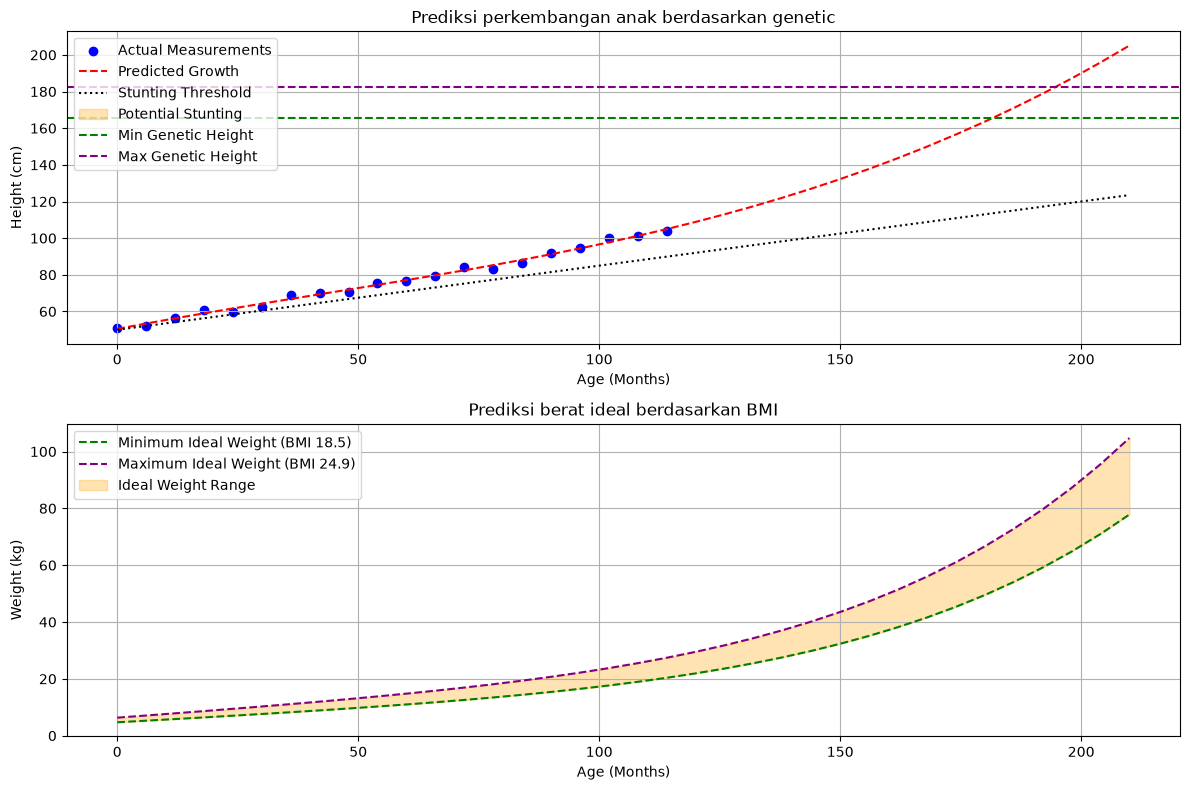

In [9]:
#Visualsiasi
plt.figure(figsize=(12, 8))
#Plot tinggi
plt.subplot(2, 1, 1)
plt.scatter(df_growth['Months'], df_growth['Height'], color='blue', label='Actual Measurements')
plt.plot(future_months, future_heights, color='red', linestyle='--', label='Predicted Growth')
plt.plot(future_months, stunting_threshold, color='black', linestyle=':', label='Stunting Threshold')
plt.fill_between(future_months, future_heights, stunting_threshold, where=is_stunted, color='orange', 
                 alpha=0.3, label='Potential Stunting')
plt.axhline(min_expected_height, color='green', linestyle='--', label='Min Genetic Height')
plt.axhline(max_expected_height, color='purple', linestyle='--', label='Max Genetic Height')
plt.xlabel('Age (Months)')
plt.ylabel('Height (cm)')
plt.title("Prediksi perkembangan anak berdasarkan genetic")
plt.legend(loc='upper left')
plt.grid(True)
#Plot berat
plt.subplot(2, 1, 2)
plt.plot(future_months, min_weights, label='Minimum Ideal Weight (BMI 18.5)', color='green', linestyle='--')
plt.plot(future_months, max_weights, label='Maximum Ideal Weight (BMI 24.9)', color='purple', linestyle='--')
plt.fill_between(future_months, min_weights, max_weights, color='orange', alpha=0.3, label='Ideal Weight Range')
plt.xlabel('Age (Months)')
plt.ylabel('Weight (kg)')
plt.title("Prediksi berat ideal berdasarkan BMI")
plt.legend(loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()